# TP2 - Parte 1: dataset y preprocesamiento

Notebook de documentación y tratamiento del dataset **70 Dog Breeds Image Dataset**: análisis
exploratorio, control de calidad, conjunto independiente de evaluación, preprocesamiento,
data augmentation y splits (ver `ENUNCIADO.md`, sección 3).

Tiene que poder leerse como un informe: celdas Markdown que explican qué se hace y por qué,
código y salidas (gráficos y tablas) **ejecutadas y guardadas**. Una notebook sin salidas
visibles se considera no entregada.

Lo que produce esta notebook lo reutilizan `2-train.ipynb` y `train_classifier`: los splits
finales (CSV/JSON con rutas y etiquetas), el conjunto independiente y el preprocesamiento
encapsulado en un módulo de `src/lib/`.

## Equipo
- Alumno 1 : Máximo Alva
- Alumno 2 : Zahir Jacob

## 1. Configuración del entorno

La configuración se define por variables de entorno **antes** de importar `lib`.

In [1]:
import os
import sys
from pathlib import Path

import cv2
from dotenv import load_dotenv
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from ultralytics import YOLO

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

os.environ["DATA_PATH"] = str(ROOT / "data")
os.environ["DATASET_PATH"] = str(ROOT / "data" / "dataset")
os.environ["OUTPUT_PATH"] = str(ROOT / "output")
os.environ["MODEL_PATH"] = str(ROOT / "models")
os.environ["USE_PGVECTOR"] = "false"
load_dotenv(ROOT / ".env.local.example")

from lib.config import settings
from lib.dataset import normalize_breed_folders

# Dataset
DATASET = Path(settings.dataset_path)
SPLITS = ("train", "valid", "test")

# Reproducibilidad
SEED = 42

# YOLO
YOLO_WEIGHTS = Path(settings.model_path) / Path(settings.yolo_model).name
YOLO_DOG_CLASS_ID = settings.yolo_dog_class_id
YOLO_CONF_THRESHOLD = settings.yolo_conf_threshold
DETECTIONS_CONF_MIN = 0.10 # confianza mínima de las detecciones guardadas en caché
DETECTIONS_CSV = Path(settings.data_path) / "processed" / f"yolo_detections_{YOLO_WEIGHTS.stem}.csv"

print("dataset_path:", settings.dataset_path)
print("GPU disponible:", torch.cuda.is_available())
print(f"YOLO: {YOLO_WEIGHTS.name}")
print(f"YOLO_CONF_THRESHOLD: {YOLO_CONF_THRESHOLD}")

dataset_path: d:\Documentos\TUIA\5C\Computer Vision\tuia-dog-recognition-app\data\dataset
GPU disponible: True
YOLO: yolo11n.pt
YOLO_CONF_THRESHOLD: 0.25


## 2. Descargar el dataset

In [2]:
#!python scripts/download_dataset.py
#!ls data/dataset

## 3. Descripción del dataset

TO-DO:
- Cantidad de razas, imágenes por raza en cada split, formato, resolución y licencia de uso.
- Cómo están encuadradas las imágenes, comparado con los recortes de YOLO que va a recibir el
  clasificador en la Etapa 3.
- Limitaciones del dataset (razas parecidas, sesgos, etc.) y cómo pueden afectar los resultados.

### 3.1. Contenido declarado

Según la página del dataset [70 Dog Breeds-Image Data Set](https://www.kaggle.com/datasets/gpiosenka/70-dog-breedsimage-data-set) en Kaggle, el dataset contiene **9346 imágenes** de **70 razas de perro**, organizadas en una carpeta por raza y divididas en `train` (7946), `valid` (700) y `test` (700). Todas están en formato **JPG**, de **224×224** píxeles y 3 canales **RGB**. El autor afirma además que un modelo entrenado con el dataset funciona bien con perros de raza pura y "razonablemente bien" con mestizos, pero no presenta evidencia.

Estos son los datos declarados, en la sección 4 (EDA) los verificaremos contra los archivos.

### 3.2. Licencia de uso

El dataset se distribuye bajo **CC0 1.0 Universal** (public domain): permite copiar, modificar y distribuir las imágenes, incluso con fines comerciales, sin pedir permiso ni exigir atribución. El uso académico de este trabajo está cubierto.

### 3.3. Limitaciones del dataset

Con lo que declara el dataset, antes de cualquier análisis, observamos estas limitaciones:

1. **No todas las clases son razas de perro.** *Coyote*, *Dhole*, *Dingo* y *African Wild Dog* son cánidos salvajes. Para el clasificador son clases visualmente distintas, pero el dataset mezcla razas con especies. Por lo pronto, decidimos mantenerlos porque forman parte del dataset provisto.

2. **Ausencia de mestizos y conjunto cerrado.** Las únicas cruzas son *Cockapoo* y *Labradoodle* y no hay perros mestizos, aunque el autor afirma sin evidencia que el modelo funciona con ellos. El clasificador es de **conjunto cerrado**: ante un mestizo o una raza que no está entre las 70, igual responde una de las 70, a veces con confianza alta. Por eso son importantes `SIMILARITY_THRESHOLD` (Etapa 1) y un umbral de *softmax* para devolver `"unknown"` (Etapa 3).

3. **Razas muy parecidas entre sí.** Hay grupos que se distinguen por detalles (pelo, orejas, tamaño), muchos de los cuales se pierden a 224×224:
   - *Collie* / *Border Collie* / *Bearded Collie*
   - *German Sheperd* / *Malinois* / *Groenendael*
   - *Bulldog* / *French Bulldog* / *Boston Terrier*
   - *Chinese Crested* / *Mex Hairless* / *American Hairless*
   - *Lhasa* / *Shih-Tzu* / *Maltese*
   - *Labrador* / *Golden Retriever*, y *Poodle* / *Labradoodle* / *Cockapoo*
   - *Cocker* / *American Spaniel* / *Irish Spaniel*

   Es esperable que la mayoría de los errores se concentren en estos grupos, así que la matriz de confusión de la notebook 2 hay que analizarla por pares y no solo con la accuracy global.

4. **Resolución fija.** Las imágenes vienen ya redimensionadas a 224×224: se perdieron la resolución y la relación de aspecto originales, y no se puede aprovechar una entrada de mayor resolución.

5. **Sesgo de origen web y posible ruido de etiquetas.** Las imágenes vienen de internet, donde predominan perros adultos, en poses de catálogo, bien iluminados y con los colores más típicos de cada raza. Cachorros, colores poco comunes y fotos de baja calidad probablemente están subrepresentados, así que el modelo puede rendir peor justo en las fotos que sube un usuario real. Además, la etiqueta es el nombre de la carpeta y el dataset no documenta cómo se verificó, así que puede haber imágenes mal etiquetadas o duplicadas.

6. **Nombres de clase con errores de ortografía** (*Dalmation*, *German Sheperd*, *Bermaise*, *Great Perenees*). Son consistentes en los tres splits, así que no afectan al entrenamiento. **Decidimos no corregirlos** para no alejarnos del dataset original; solo afectan a cómo se muestra la raza en la app.

## 4. Análisis exploratorio (EDA)

TO-DO:
- Distribución de clases: imágenes por raza en cada split (gráfico y estadísticas). Desbalance.
- Resoluciones, relación de aspecto, canales, formatos y archivos corruptos.
- Grilla de ejemplos por raza, incluyendo pares de razas fáciles de confundir.
- Variaciones: iluminación, pose, fondo, oclusiones y cantidad de perros por imagen.

### 4.1. Inventario de archivos

Recorremos el dataset para armar un `DataFrame` con **una fila por imagen**: split, raza, ruta (relativa a `data/dataset`), extensión, tamaño en disco y metadata de la imagen (ancho, alto, modo de color y formato).

In [3]:
def build_inventory(dataset_dir: Path, splits: tuple[str, ...]) -> pd.DataFrame:
    """
    Arma un inventario de las imágenes del dataset, con metadata como raza, ruta,
    extensión, tamaño y propiedades de la imagen.

    Args:
        dataset_dir (Path): Carpeta raíz del dataset.
        splits (tuple[str, ...]): Splits a recorrer (por ejemplo, ("train", "valid", "test")).

    Returns:
        pd.DataFrame: Inventario con una fila por imagen y su metadata.
    """
    rows = []
    for split in splits:
        for breed_dir in sorted(p for p in (dataset_dir / split).iterdir() if p.is_dir()):
            for f in sorted(p for p in breed_dir.iterdir() if p.is_file()):
                row = {
                    "split": split,
                    "breed": breed_dir.name,
                    "path": f.relative_to(dataset_dir).as_posix(),
                    "ext": f.suffix.lower(),
                    "size_kb": f.stat().st_size / 1024,
                }
                try:
                    with Image.open(f) as im:  # lee solo el header, no decodifica
                        row.update(width=im.width, height=im.height,
                                   mode=im.mode, format=im.format, opens=True)
                except Exception:
                    row.update(width=None, height=None, mode=None, format=None, opens=False)
                rows.append(row)
    return pd.DataFrame(rows)

In [4]:
df = build_inventory(DATASET, SPLITS)
print(f"Total de archivos: {len(df)}")
df.head()

Total de archivos: 9346


,split,breed,path,ext,size_kb,width,height,mode,format,opens
0,train,Afghan,train/Afghan/001.jpg,.jpg,19.914062,224,224,RGB,JPEG,True
1,train,Afghan,train/Afghan/002.jpg,.jpg,20.272461,224,224,RGB,JPEG,True
2,train,Afghan,train/Afghan/003.jpg,.jpg,21.757812,224,224,RGB,JPEG,True
3,train,Afghan,train/Afghan/004.jpg,.jpg,16.305664,224,224,RGB,JPEG,True
4,train,Afghan,train/Afghan/005.jpg,.jpg,24.864258,224,224,RGB,JPEG,True


### 4.2. Consistencia de etiquetas

Antes de contar razas se verifica que los tres splits tengan exactamente el mismo conjunto de nombres. La etiqueta de cada imagen es el nombre de su carpeta.

In [5]:
def report_breeds(df: pd.DataFrame) -> None:
    """
    Imprime cuántas razas hay en total y en cada split, y cuáles faltan en cada uno.
    
    Args:
        df (pd.DataFrame): Inventario de imágenes con columna "breed" y "split".
    """
    breeds_per_split = df.groupby("split")["breed"].unique().apply(set)
    all_names = set().union(*breeds_per_split)
    print(f"Razas totales: {len(all_names)}")
    for split in SPLITS:
        missing = all_names - breeds_per_split[split]
        print(f"Razas {split:7s}: {len(breeds_per_split[split])}"
                + (f" | Raza/s faltante/s: {sorted(missing)}" if missing else ""))

In [6]:
report_breeds(df)

Razas totales: 70
Razas train  : 70
Razas valid  : 70
Razas test   : 70


En el dataset original hay 71 razas en total y en cada split hay 70, es decir, a todos les falta 1. La raza *American Spaniel* figura como
`American Spaniel` en `train` y `test`, y como `American  Spaniel` (dos espacios) en `valid`. Sin corregirlo, las imágenes de esa raza en `valid` tendrían una etiqueta que no existe en `train` por lo que el modelo nunca podría acertarlas y la accuracy de validación quedaría sesgada.

Tomamos la decisión de renombrar las carpetas en disco. `scripts/build_index.py` y
`torchvision.datasets.ImageFolder` toman la raza directamente del nombre de la carpeta, así que corregirlo
solo en el `DataFrame` obligaría a parchear cada lugar que lea el dataset. Renombrar la carpeta deja un
único punto de corrección.

Para que sea reproducible, la corrección está en `src/lib/dataset.py` (`normalize_breed_folders`), esta función colapsa los espacios repetidos de los nombres de carpeta y es idempotente. Se llama acá y también en `scripts/download_dataset.py`, así cualquier nueva descarga queda automáticamente corregida.

In [7]:
renamed = normalize_breed_folders(DATASET, SPLITS)
if renamed:
    df = build_inventory(DATASET, SPLITS) # se rehace el inventario con los nombres corregidos
else:
    print("Las carpetas ya estaban normalizadas, no se renombró nada.")

Las carpetas ya estaban normalizadas, no se renombró nada.


In [8]:
report_breeds(df)

Razas totales: 70
Razas train  : 70
Razas valid  : 70
Razas test   : 70


### 4.3. Distribución de clases

In [9]:
counts = df.pivot_table(index="breed", columns="split", values="path", aggfunc="count", fill_value=0)[list(SPLITS)]

summary = pd.DataFrame({
    "razas": (counts > 0).sum(),
    "imágenes": counts.sum(),
    "% del total": (counts.sum() / counts.values.sum() * 100).round(1),
}).T
summary

split,train,valid,test
razas,70.0,70.0,70.0
imágenes,7946.0,700.0,700.0
% del total,85.0,7.5,7.5


El dataset tiene **9346 imágenes de 70 razas**, divididas en `train` (7946, 85 %), `valid` (700, 7,5 %) y `test` (700, 7,5 %). Las 70 razas están presentes en los tres splits. Coincide con lo declarado en Kaggle (3.1).

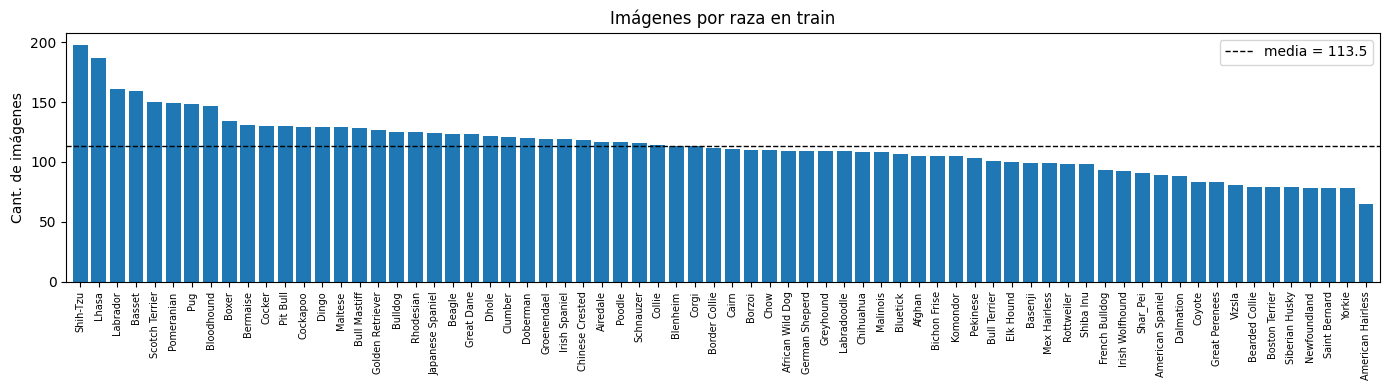

In [10]:
train_counts = df[df["split"] == "train"]["breed"].value_counts().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(train_counts.index, train_counts.values)
ax.axhline(train_counts.mean(), color="k", ls="--", lw=1, label=f"media = {train_counts.mean():.1f}")
ax.set(title="Imágenes por raza en train", ylabel="Cant. de imágenes")
ax.tick_params(axis="x", rotation=90, labelsize=7)
ax.margins(x=0.005)
ax.legend()
plt.tight_layout()
plt.show()

In [11]:
print("Imágenes por raza en train:")
print(f"* Media:   {train_counts.mean():.1f}")
print(f"* Mediana: {train_counts.median():.1f}")
print(f"* Mínimo:  {train_counts.min()} ({train_counts.idxmin()})")
print(f"* Máximo:  {train_counts.max()} ({train_counts.idxmax()})")

Imágenes por raza en train:
* Media:   113.5
* Mediana: 111.5
* Mínimo:  65 (American Hairless)
* Máximo:  198 (Shih-Tzu)


**Desbalance en `train`.** Las razas tienen entre 65 (*American Hairless*) y 198 (*Shih-Tzu*) imágenes: la más
representada tiene 3 veces más que la menos representada. Pero el desbalance es **moderado**: la mayoría de
las razas está entre ~80 y ~130 imágenes, cerca de la media (113,5), y los extremos son pocos.

Cómo puede afectar:
- El modelo tiende a favorecer a las clases frecuentes cuando duda. Esto preocupa más **dentro de los grupos de razas parecidas**: *Lhasa* y *Shih-Tzu*, las dos razas con más imágenes, son justamente un par fácil de confundir con *Maltese*. Es esperable que en la duda el modelo se incline hacia la raza con más ejemplos.
- La accuracy global puede ocultarlo, porque las razas grandes pesan más en `train` (en `valid` y `test` no, porque están balanceados).

Evaluaremos cómo mitigarlo y qué decisión tomar en el notebook 2.

In [12]:
print(f"Imágenes por raza en valid y test: {df[df['split'] != 'train'].groupby(['split', 'breed']).size().unique()}")

Imágenes por raza en valid y test: [10]


**¿Alcanza el tamaño de `valid` y `test` para métricas por raza estables?** No. Con 10 imágenes por raza,
cada imagen vale 10 pp de accuracy: una raza con 8 aciertos (80 %) y otra con 9 (90 %) se diferencian en una
sola imagen, que puede ser una foto difícil o mal etiquetada. Las métricas por raza (y el ranking de "peores
razas" de la notebook 2) hay que leerlas como **tendencias**, no como diferencias reales. En cambio, las
métricas **globales** se calculan sobre 700 imágenes: una imagen mueve la accuracy en apenas 0,14 pp, así
que son estables y sirven para comparar modelos.

### 4.4. Formato, resolución y canales

In [13]:
res = df["width"].astype("Int64").astype(str) + "x" + df["height"].astype("Int64").astype(str)

for title, series in [("Formatos", df["format"]), ("Extensiones", df["ext"]),
                      ("Modos de color", df["mode"]), ("Resoluciones", res)]:
    print(f"{title}:")
    print(series.value_counts(dropna=False).rename_axis(None).to_string(), end="\n")

print(f"Tamaño en disco:\n{df['size_kb'].sum() / 1024:.1f} MB (media {df['size_kb'].mean():.1f} KB por imagen)")

Formatos:
JPEG    9346
Extensiones:
.jpg    9346
Modos de color:
RGB    9346
Resoluciones:
224x224    9346
Tamaño en disco:
215.0 MB (media 23.6 KB por imagen)


Según el encabezado, las 9346 imágenes son **JPEG, RGB y de 224×224 píxeles**. Como hay una única resolución, la relación de aspecto se reduce a un solo valor (1:1). La resolución fija confirma que las imágenes ya vienen recortadas y/o redimensionadas, y no se puede conocer su relación de aspecto original.

In [14]:
def pixel_stats(path: Path, gray_chroma_max: int = 10) -> dict:
    """
    Decodifica la imagen completa y calcula estadísticas de píxeles.
    
    Args:
        path (Path): ruta a la imagen.
        gray_chroma_max (int): umbral para determinar si una imagen es gris.


    Returns:
        dict: decodes (si se pudo decodificar entera), is_gray (si no tiene color aunque sea RGB),
        brightness (media de la luminancia, 0-255) y contrast (desvío de la luminancia).
    """
    try:
        with Image.open(path) as im:
            arr = np.asarray(im.convert("RGB"), dtype=np.float32)  # convert() fuerza la decodificación completa
    except Exception:
        return {"decodes": False, "is_gray": None, "brightness": None, "contrast": None}
    lum = arr @ np.array([0.299, 0.587, 0.114], dtype=np.float32)  # luminancia percibida
    chroma = np.percentile(arr.max(axis=2) - arr.min(axis=2), 99)  # color del 1 % de píxeles más coloridos
    return {"decodes": True, "is_gray": bool(chroma < gray_chroma_max),
            "brightness": float(lum.mean()), "contrast": float(lum.std())}

Una imagen guardada como RGB puede no tener color, en una foto en blanco y negro los tres canales son iguales.
Para detectarlas medimos, en cada píxel, la diferencia entre el canal máximo y el mínimo (0 si no hay color), y
tomamos el valor del 1 % de píxeles más coloridos (percentil 99). Si es menor que 10 (margen para el ruido del
JPEG), la imagen se considera en escala de grises.

In [15]:
pix = pd.DataFrame([pixel_stats(DATASET / p) for p in df["path"]], index=df.index)
df = df.join(pix)

print(f"Archivos que no se decodifican completos: {(~df['decodes']).sum()}")
print(f"Imágenes sin color (grises guardadas como RGB): {df['is_gray'].sum()}")

Archivos que no se decodifican completos: 0
Imágenes sin color (grises guardadas como RGB): 43


La decodificación completa confirma que **ninguna imagen está corrupta**.

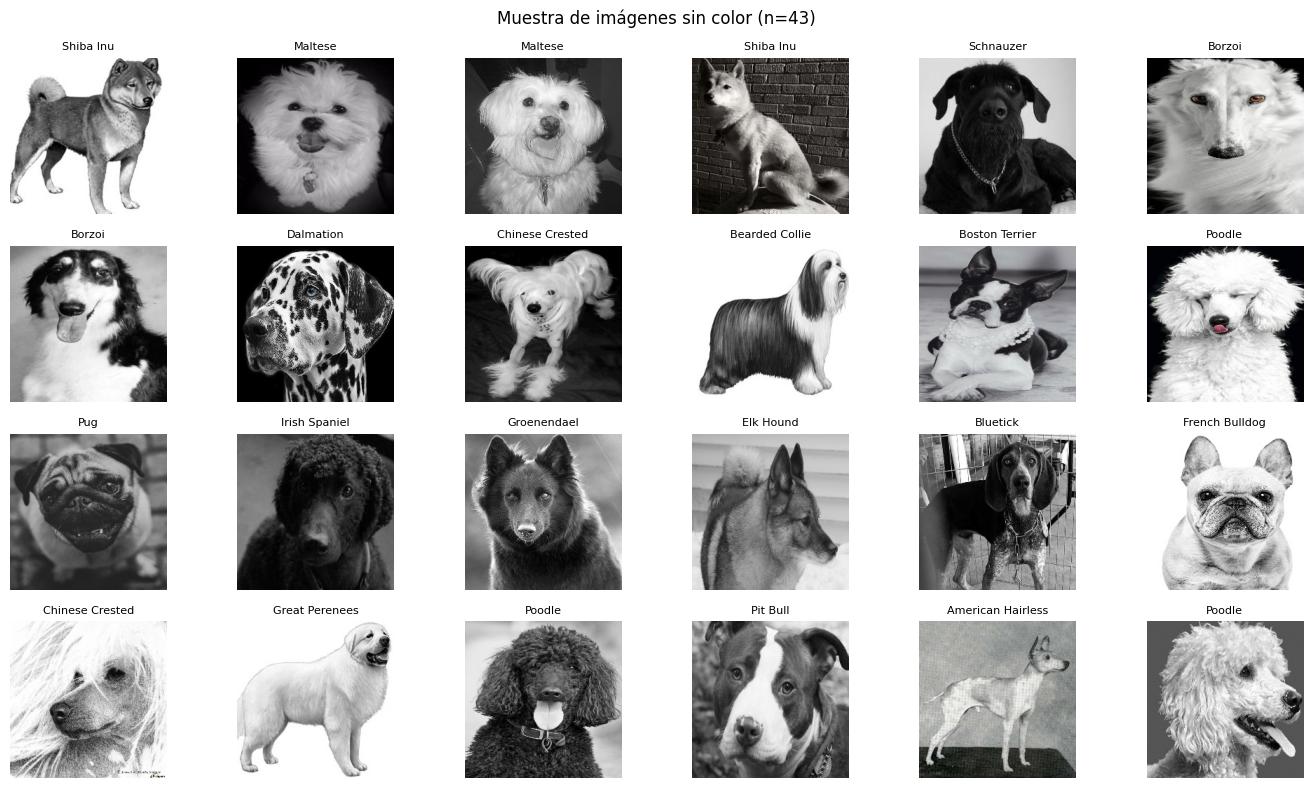

In [16]:
grises = df[df["is_gray"]]

muestra = grises.sample(min(24, len(grises)), random_state=SEED)
fig, axes = plt.subplots(4, 6, figsize=(14, 8))
for ax, (_, r) in zip(axes.flat, muestra.iterrows()):
    ax.imshow(Image.open(DATASET / r["path"]))
    ax.set_title(r["breed"], fontsize=8)
for ax in axes.flat:
    ax.axis("off")
plt.suptitle(f"Muestra de imágenes sin color (n={len(grises)})")
plt.tight_layout()
plt.show()

**43 imágenes (0,5 %) están en escala de grises**. No las descartaremos: son pocas, están bien etiquetadas y, como tienen 3 canales, no necesitan un tratamiento especial en el preprocesamiento. Sí representan una **limitación** ya que el modelo casi no ve imágenes sin color. Una foto en blanco y negro en la app sería un caso muy raro. Sin embargo, conservar estas imágenes puede contribuir a la robustez del modelo.

### 4.5. Muestra visual

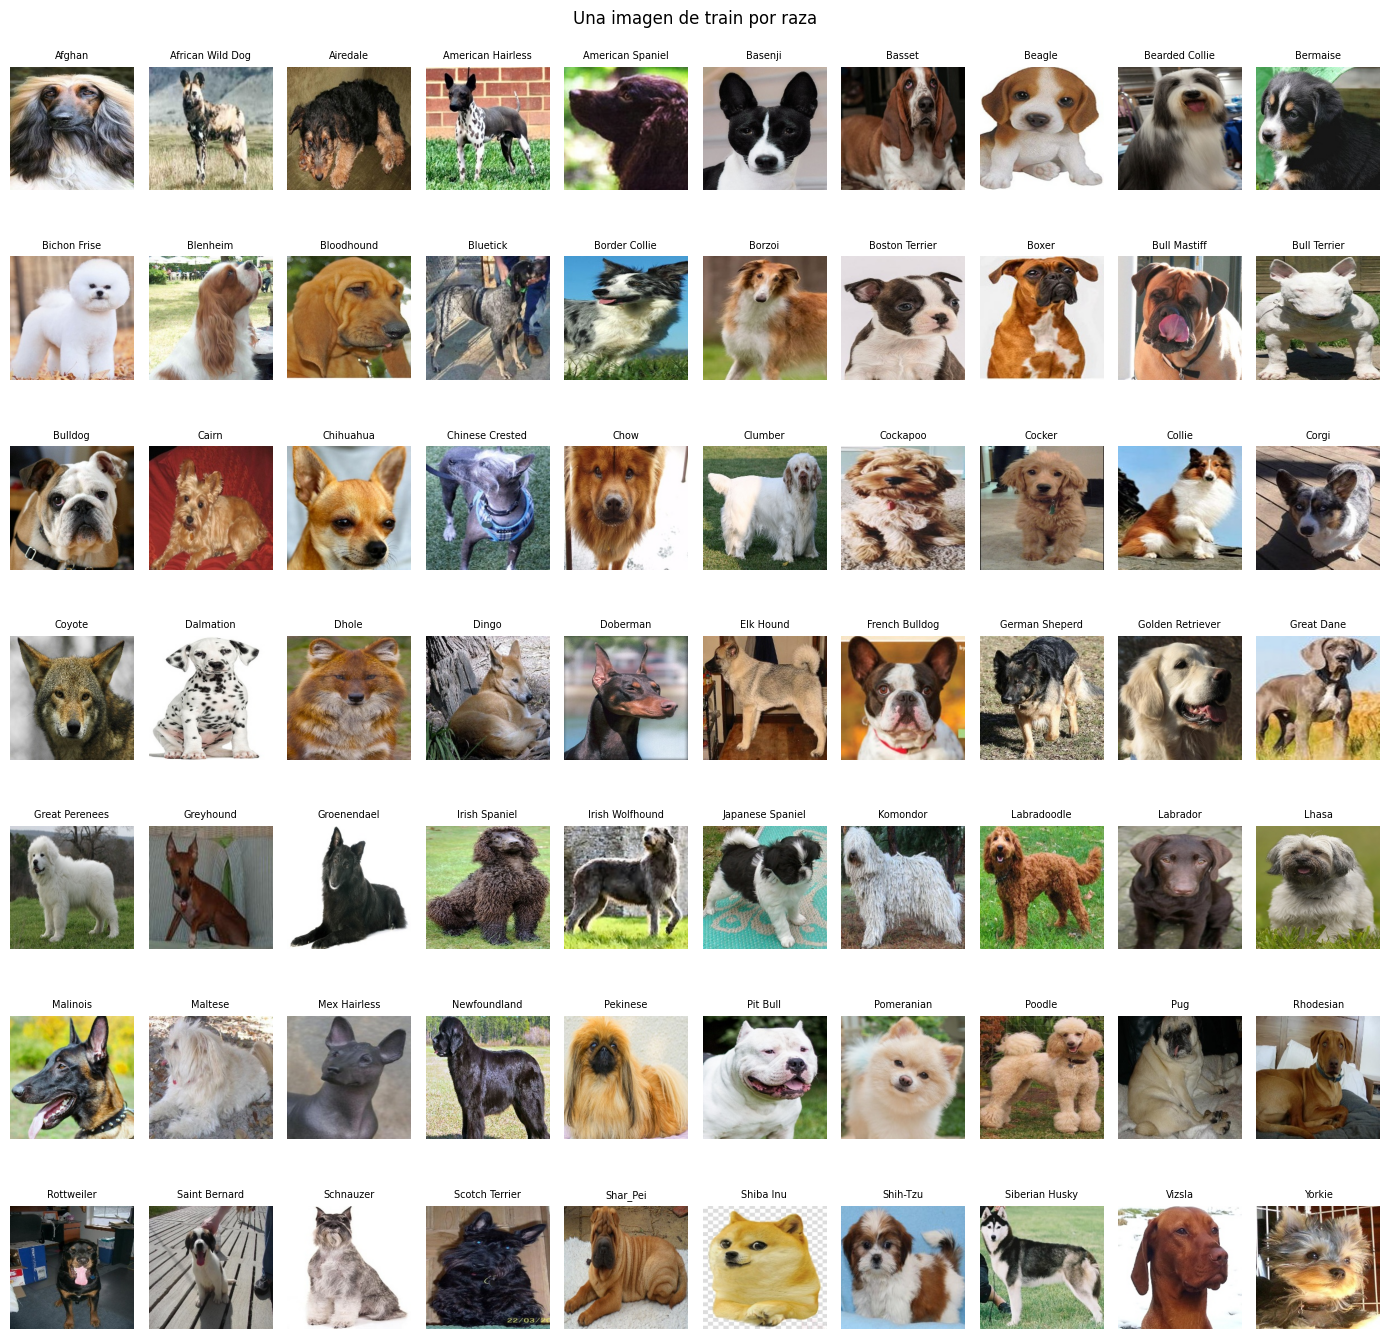

In [35]:
ejemplos = df[df["split"] == "train"].groupby("breed").sample(1, random_state=SEED)

fig, axes = plt.subplots(7, 10, figsize=(14, 14))
for ax, (_, r) in zip(axes.flat, ejemplos.iterrows()):
    ax.imshow(Image.open(DATASET / r["path"]))
    ax.set_title(r["breed"], fontsize=7)
for ax in axes.flat:
    ax.axis("off")
plt.suptitle("Una imagen de train por raza", fontsize=12)
plt.tight_layout()
plt.show()

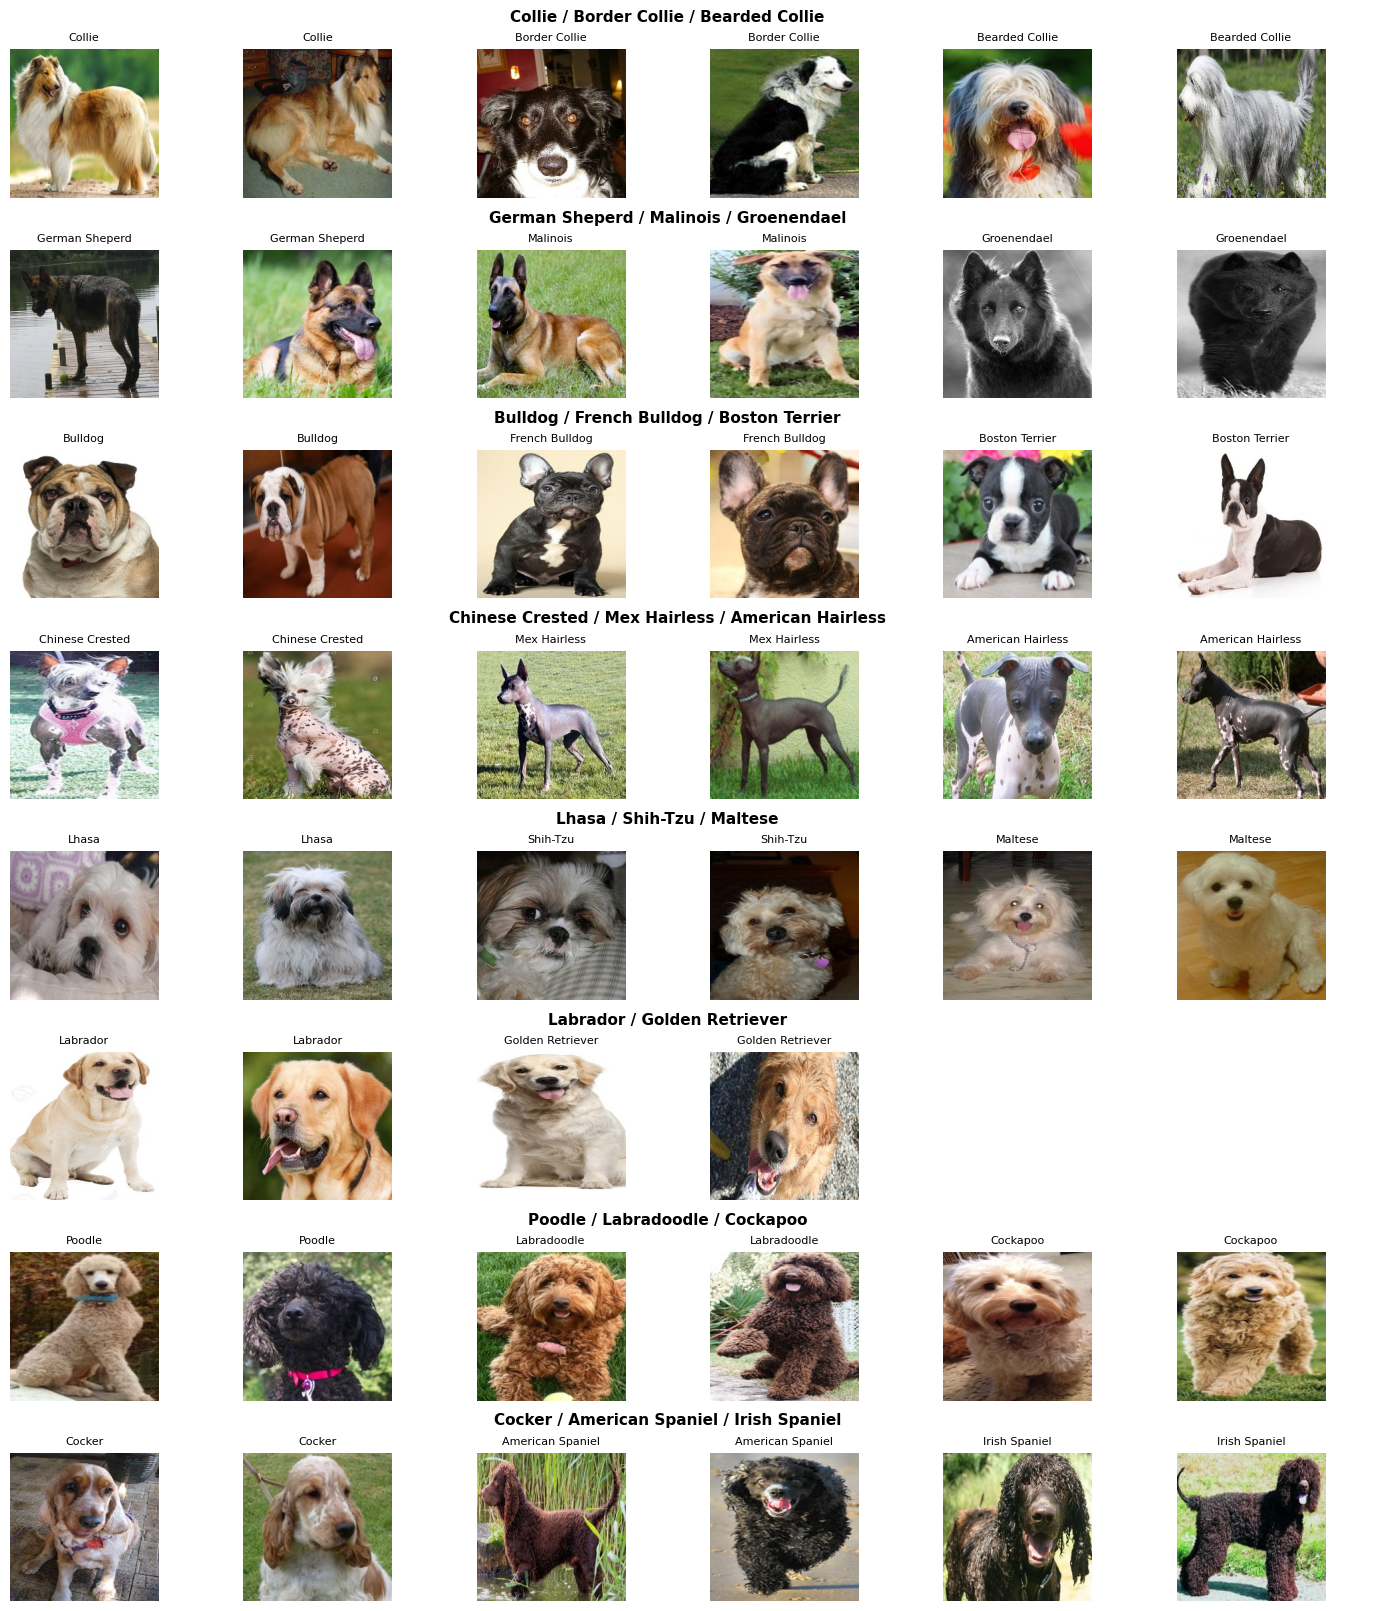

In [36]:
GRUPOS_PARECIDOS = [
    ["Collie", "Border Collie", "Bearded Collie"],
    ["German Sheperd", "Malinois", "Groenendael"],
    ["Bulldog", "French Bulldog", "Boston Terrier"],
    ["Chinese Crested", "Mex Hairless", "American Hairless"],
    ["Lhasa", "Shih-Tzu", "Maltese"],
    ["Labrador", "Golden Retriever"],
    ["Poodle", "Labradoodle", "Cockapoo"],
    ["Cocker", "American Spaniel", "Irish Spaniel"],
]
IMGS_POR_RAZA = 2

train = df[df["split"] == "train"]
fig = plt.figure(figsize=(14, 2 * len(GRUPOS_PARECIDOS)), layout="constrained")
for subfig, grupo in zip(fig.subfigures(len(GRUPOS_PARECIDOS), 1), GRUPOS_PARECIDOS):
    subfig.suptitle(" / ".join(grupo), fontsize=11, fontweight="bold")
    axes = subfig.subplots(1, 3 * IMGS_POR_RAZA)
    for ax in axes:
        ax.axis("off")
    for j, breed in enumerate(grupo):
        muestra = train[train["breed"] == breed].sample(IMGS_POR_RAZA, random_state=SEED)
        for k, (_, r) in enumerate(muestra.iterrows()):
            ax = axes[j * IMGS_POR_RAZA + k]
            ax.imshow(Image.open(DATASET / r["path"]))
            ax.set_title(breed, fontsize=8)
plt.show()

**Qué muestran las grillas**

- **Fondos y poses variados.** Hay fondos de exterior (pasto, playa, nieve), de estudio (blanco liso) e
  interiores, y poses de todo tipo: de perfil, sentados, acostados y primeros planos de la cabeza. La mayoría
  son fotos de buena calidad, con el perro centrado y bien iluminado.
- **Hay cachorros**, por ejemplo en *Beagle*, *Bermaise*, *Boston Terrier*, *Japanese Spaniel* o *Shih-Tzu*,
  así que no están tan subrepresentados como suponíamos en 3.3. Dentro de una misma raza también hay distintos
  colores de pelo (por ejemplo, *Poodle* damasco y negro).
- **Imágenes poco "fotográficas".** Además de las ilustraciones de 4.4, aparecen un meme recortado sobre fondo
  transparente (*Shiba Inu*), fechas impresas en la foto (*Scotch Terrier*) y marcas de agua de bancos de
  imágenes (*Labrador*, *Chinese Crested*). Si un mismo artefacto se repite en una clase, el modelo podría
  aprender a asociarlo con la raza.
- **Los grupos de razas parecidas se confirman en su mayoría.** *Lhasa* / *Shih-Tzu* / *Maltese*,
  *Labrador* / *Golden Retriever*, *Poodle* / *Labradoodle* / *Cockapoo* y *American Spaniel* / *Irish
  Spaniel* son muy difíciles de distinguir incluso a ojo. En otros grupos hay una raza que se separa con
  facilidad: el *Groenendael* (negro) frente al *German Sheperd* y el *Malinois*, o el *Bearded Collie* (pelo
  largo y gris) frente a los otros collies.
- **Posible etiqueta dudosa.** El segundo *Malinois* es un perro de pelo largo y claro que no se parece a la
  raza. Es un ejemplo del ruido de etiquetas que mencionamos en 3.3, y se revisa en la sección 5.

### 4.6. Variaciones

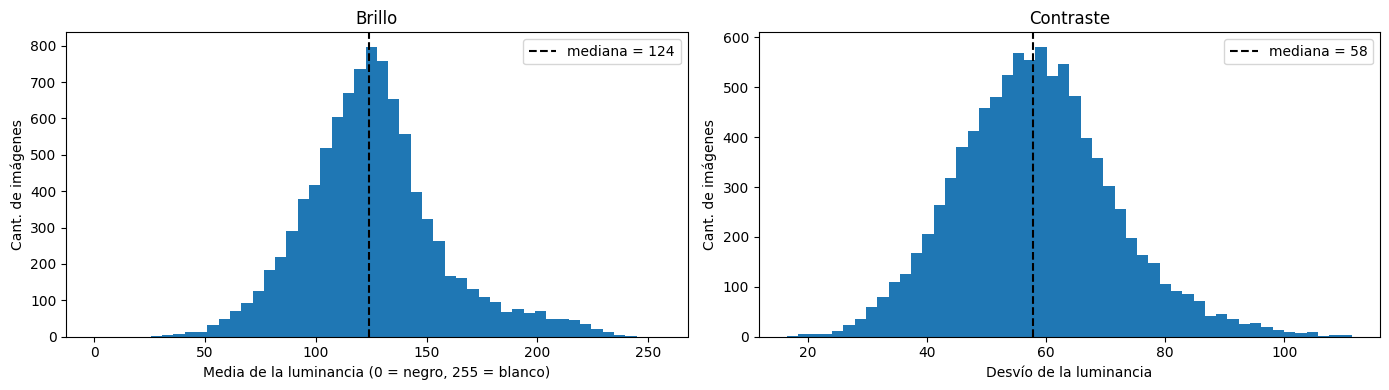

In [37]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

ax1.hist(df["brightness"], bins=50, range=(0, 255))
ax1.axvline(df["brightness"].median(), color="k", ls="--", label=f"mediana = {df['brightness'].median():.0f}")
ax1.set(title="Brillo", xlabel="Media de la luminancia (0 = negro, 255 = blanco)", ylabel="Cant. de imágenes")
ax1.legend()

ax2.hist(df["contrast"], bins=50)
ax2.axvline(df["contrast"].median(), color="k", ls="--", label=f"mediana = {df['contrast'].median():.0f}")
ax2.set(title="Contraste", xlabel="Desvío de la luminancia", ylabel="Cant. de imágenes")
ax2.legend()

plt.tight_layout()
plt.show()

In [38]:
brillo_raza = df.groupby("breed")["brightness"].median().sort_values()
print("Razas con menor brillo mediano:")
print(brillo_raza.head(5).round(0).to_string())
print("\nRazas con mayor brillo mediano:")
print(brillo_raza.tail(5).round(0).to_string())

Razas con menor brillo mediano:
breed
Irish Spaniel        98.0
Bermaise             98.0
Groenendael         101.0
Rottweiler          103.0
American Spaniel    111.0

Razas con mayor brillo mediano:
breed
Komondor          138.0
Maltese           140.0
Great Perenees    144.0
Shiba Inu         146.0
Bichon Frise      154.0


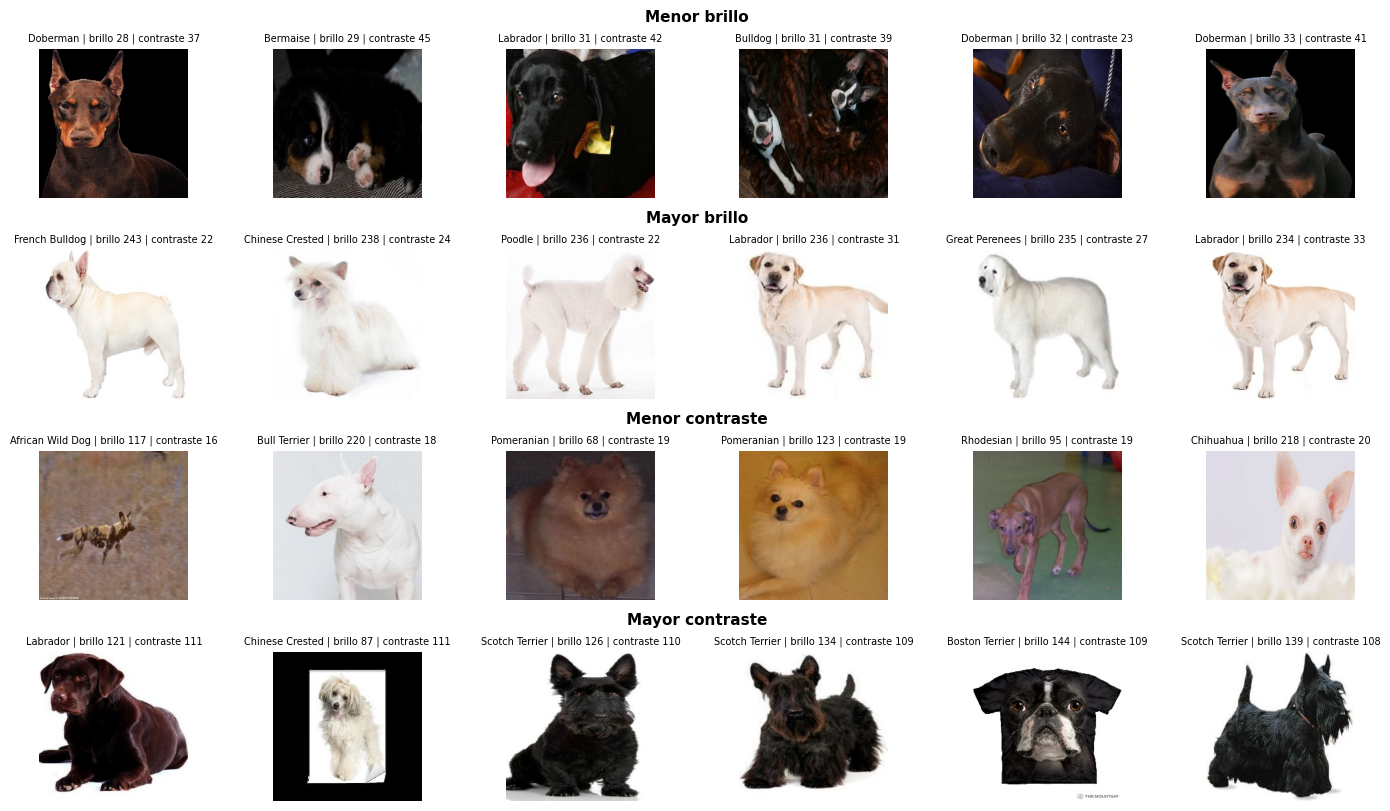

In [41]:
extremos = {
    "Menor brillo": df.nsmallest(6, "brightness"),
    "Mayor brillo": df.nlargest(6, "brightness"),
    "Menor contraste": df.nsmallest(6, "contrast"),
    "Mayor contraste": df.nlargest(6, "contrast"),
}
fig = plt.figure(figsize=(14, 2 * len(extremos)), layout="constrained")
for subfig, (nombre, sub) in zip(fig.subfigures(len(extremos), 1), extremos.items()):
    subfig.suptitle(nombre, fontsize=11, fontweight="bold")
    for ax, (_, r) in zip(subfig.subplots(1, 6), sub.iterrows()):
        ax.imshow(Image.open(DATASET / r["path"]))
        ax.set_title(f"{r['breed']} | brillo {r['brightness']:.0f} | contraste {r['contrast']:.0f}", fontsize=7)
        ax.axis("off")
plt.show()

**Iluminación.** El brillo se concentra alrededor de 124 (sobre 255) y el contraste alrededor de 58, con
distribuciones bastante simétricas y sin imágenes casi negras ni quemadas (el brillo va de 28 a 243). La cola
de brillo alto corresponde a fotos de estudio con fondo blanco.

El brillo **no mide solo la iluminación, también el color del perro**: las razas con menor brillo mediano son
de pelo oscuro (*Irish Spaniel*, *Bermaise*, *Groenendael*, *Rottweiler*) y las de mayor brillo, de pelo blanco
(*Bichon Frise*, *Great Perenees*, *Maltese*, *Komondor*). Los extremos lo confirman: las imágenes más oscuras
son perros negros sobre fondo negro y las más claras, perros blancos sobre fondo blanco, todas bien expuestas.
Por eso, **un umbral de brillo no sirve como regla de descarte** en el control de calidad (sección 5): eliminaría
justamente las razas oscuras o claras. El contraste bajo, en cambio, sí señala algunas fotos borrosas o
lavadas, que se tratan con la regla de imágenes borrosas.

Los extremos también muestran imágenes que **no son fotos de un perro real**, una remera estampada (*Boston
Terrier*) y una foto de una foto impresa (*Chinese Crested*), y **posibles duplicados** (los dos *Labrador* de
mayor brillo parecen la misma imagen). Ambos casos se revisan en la sección 5.

**Pose y fondo.** Como se vio en las grillas de 4.5, hay variedad de poses (de perfil, sentados, acostados,
primeros planos de la cabeza) y de fondos (exterior, estudio, interiores). La cantidad de perros por imagen y
las oclusiones (perros cortados por el encuadre) se miden en 4.7.

### 4.7. Encuadre de las imágenes vs. recortes de YOLO

En la Etapa 3, el clasificador recibe recortes producidos por YOLO sobre fotos arbitrarias. Si el encuadre, la cantidad de fondo, la relación de aspecto o la resolución cambian entre entrenamiento e inferencia, entonces existe un cambio de dominio y la accuracy de `test` sobreestima el desempeño real.

Para caracterizar el encuadre del dataset pasamos por todas las imágenes el mismo detector que usa la app (`YOLO_MODEL`). El análisis filtra con `YOLO_CONF_THRESHOLD`, el mismo umbral de la app. Usamos los parámetros por defecto de `ultralytics`, igual que en `detect_dogs`, para medir lo que va a ver la app.

Lo que medimos por imagen:

| Medida | Qué responde |
|---|---|
| Cantidad de perros | ¿Hay otros perros en la imagen? |
| Personas / otros animales / otros objetos | ¿Hay otras entidades? |
| Fracción del área que ocupa el perro principal | ¿Ocupa casi toda la imagen? ¿Cuánto fondo hay? |
| Relación de aspecto de la caja | ¿Qué forma tendría el recorte de YOLO? |
| Lados de la caja que tocan el borde | ¿El perro está cortado por el encuadre? |

Limitación de la medida: la caja de YOLO es un rectángulo y también incluye algo de fondo, así que `1 − fracción` es una **cota inferior** del fondo.

In [19]:
def run_yolo(paths: list[str], dataset_dir: Path, weights: Path, conf_min: float, batch: int = 64) -> pd.DataFrame:
    """
    Corre YOLO sobre una lista de imágenes y devuelve todas las detecciones (clases de COCO).

    Args:
        paths (list[str]): Rutas de las imágenes relativas a `dataset_dir`.
        dataset_dir (Path): Carpeta raíz del dataset.
        weights (Path): Pesos de YOLO.
        conf_min (float): Confianza mínima para guardar una detección.
        batch (int): Imágenes por llamada a `predict`.

    Returns:
        pd.DataFrame: Una fila por detección (path, clase, confianza y bounding box).
    """
    model = YOLO(str(weights))
    rows = []
    for i in range(0, len(paths), batch):
        chunk = paths[i:i + batch]
        results = model.predict([str(dataset_dir / p) for p in chunk], conf=conf_min, verbose=False)
        for p, r in zip(chunk, results):
            for box, c, k in zip(r.boxes.xyxy.tolist(), r.boxes.conf.tolist(), r.boxes.cls.tolist()):
                rows.append([p, int(k), model.names[int(k)], c, *box])
    return pd.DataFrame(rows, columns=["path", "cls", "cls_name", "conf", "x1", "y1", "x2", "y2"])

In [20]:
if DETECTIONS_CSV.exists():
    detections = pd.read_csv(DETECTIONS_CSV)
    print(f"Detecciones leídas de {DETECTIONS_CSV.relative_to(ROOT)}")
else:
    print("Generando detecciones con YOLO...")
    detections = run_yolo(df["path"].tolist(), DATASET, YOLO_WEIGHTS, DETECTIONS_CONF_MIN)
    DETECTIONS_CSV.parent.mkdir(parents=True, exist_ok=True)
    detections.to_csv(DETECTIONS_CSV, index=False)
    print(f"Detecciones guardadas en {DETECTIONS_CSV.relative_to(ROOT)}")

print(f"Total de entidades detectadas (CONF >= {DETECTIONS_CONF_MIN}): {len(detections)}")

Detecciones leídas de data\processed\yolo_detections_yolo11n.csv
Total de entidades detectadas (CONF >= 0.1): 15999


In [21]:
YOLO_PERSON_CLASS_ID = 0
YOLO_ANIMAL_CLASS_IDS = {14, 15, 17, 18, 19, 20, 21, 22, 23} # COCO: bird, cat, horse, sheep, cow, elephant, bear, zebra, giraffe
BORDER_PX = 2  # una caja toca el borde si queda a <= 2 px

def frame_stats(df: pd.DataFrame, detections: pd.DataFrame, conf: float) -> pd.DataFrame:
    """
    Resume las detecciones de YOLO en una fila por imagen: perros, personas, otros animales, otros objetos y
    la geometría de la caja del perro principal.

    Args:
        df (pd.DataFrame): Inventario (path, split, breed, width, height).
        detections (pd.DataFrame): Detecciones de `run_yolo`.
        conf (float): Umbral de confianza a aplicar.

    Returns:
        pd.DataFrame: Inventario con las columnas de encuadre agregadas.
    """
    det = detections[detections["conf"] >= conf].merge(df[["path", "width", "height"]], on="path")
    is_dog, is_person = det["cls"] == YOLO_DOG_CLASS_ID, det["cls"] == YOLO_PERSON_CLASS_ID
    is_animal = det["cls"].isin(YOLO_ANIMAL_CLASS_IDS)

    counts = pd.DataFrame({
        "n_dogs": is_dog.groupby(det["path"]).sum(),
        "n_persons": is_person.groupby(det["path"]).sum(),
        "n_animals": is_animal.groupby(det["path"]).sum(),
        "n_objects": (~(is_dog | is_person | is_animal)).groupby(det["path"]).sum(),
    })

    dogs = det[is_dog].copy()
    dogs["box_w"], dogs["box_h"] = dogs["x2"] - dogs["x1"], dogs["y2"] - dogs["y1"]
    dogs["area_frac"] = dogs["box_w"] * dogs["box_h"] / (dogs["width"] * dogs["height"])
    dogs["aspect"] = dogs["box_w"] / dogs["box_h"]
    dogs["n_borders"] = (dogs["x1"] <= BORDER_PX).astype(int) + (dogs["y1"] <= BORDER_PX) + (dogs["x2"] >= dogs["width"] - BORDER_PX) + (dogs["y2"] >= dogs["height"] - BORDER_PX)
    main = (dogs.sort_values("area_frac", ascending=False).drop_duplicates("path").set_index("path")[["conf", "x1", "y1", "x2", "y2", "box_w", "box_h", "area_frac", "aspect", "n_borders"]])

    out = df.merge(counts, left_on="path", right_index=True, how="left")
    out = out.merge(main, left_on="path", right_index=True, how="left")
    out[counts.columns] = out[counts.columns].fillna(0).astype(int)
    
    return out

In [22]:
frame = frame_stats(df, detections, YOLO_CONF_THRESHOLD)

print(f"Cantidad de imágenes por contenido detectado (>= {YOLO_CONF_THRESHOLD} YOLO_CONF_THRESHOLD):")
print(f"* Con 0 perros:       {(frame['n_dogs'] == 0).sum():5d} ({(frame['n_dogs'] == 0).mean():.1%})")
print(f"* Con 1 perro:        {(frame['n_dogs'] == 1).sum():5d} ({(frame['n_dogs'] == 1).mean():.1%})")
print(f"* Con 2 o más perros: {(frame['n_dogs'] >= 2).sum():5d} ({(frame['n_dogs'] >= 2).mean():.1%})")
print(f"* Con personas:       {(frame['n_persons'] > 0).sum():5d} ({(frame['n_persons'] > 0).mean():.1%})")
print(f"* Con otros animales: {(frame['n_animals'] > 0).sum():5d} ({(frame['n_animals'] > 0).mean():.1%})")
print(f"* Con otros objetos:  {(frame['n_objects'] > 0).sum():5d} ({(frame['n_objects'] > 0).mean():.1%})")

Cantidad de imágenes por contenido detectado (>= 0.25 YOLO_CONF_THRESHOLD):
* Con 0 perros:        2951 (31.6%)
* Con 1 perro:         6308 (67.5%)
* Con 2 o más perros:    87 (0.9%)
* Con personas:         484 (5.2%)
* Con otros animales:  2863 (30.6%)
* Con otros objetos:   1071 (11.5%)


Imágenes con 1 o más perros: 6395


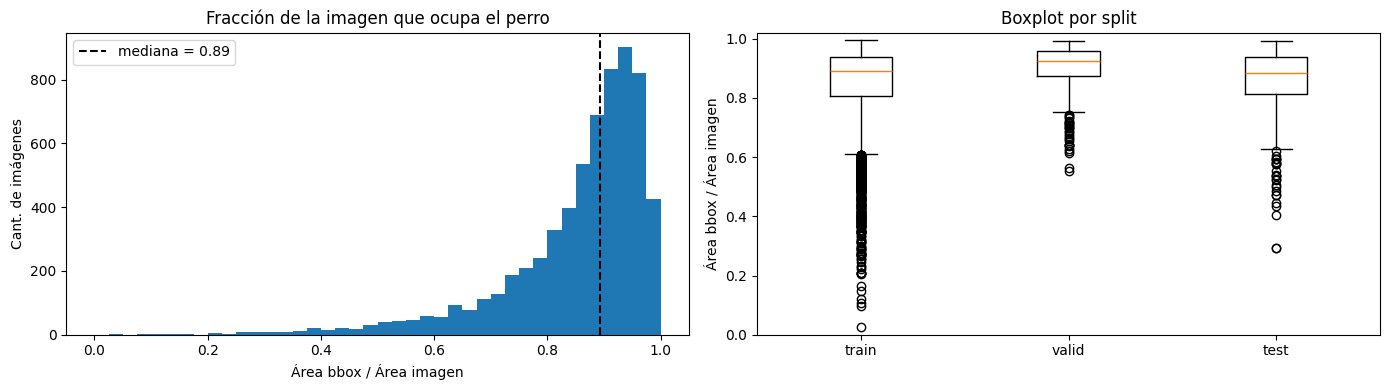

In [23]:
con_perro = frame[frame["n_dogs"] > 0]
print(f"Imágenes con 1 o más perros: {len(con_perro)}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

ax1.hist(con_perro["area_frac"], bins=40, range=(0, 1))
ax1.axvline(con_perro["area_frac"].median(), color="k", ls="--", label=f"mediana = {con_perro['area_frac'].median():.2f}")
ax1.set(title="Fracción de la imagen que ocupa el perro", xlabel="Área bbox / Área imagen", ylabel="Cant. de imágenes")
ax1.legend()

ax2.boxplot([con_perro.loc[con_perro["split"] == s, "area_frac"] for s in SPLITS], tick_labels=SPLITS)
ax2.set(title="Boxplot por split", ylabel="Área bbox / Área imagen", ylim=(0, 1.02))

plt.tight_layout()
plt.show()

Cajas con más de un 20 % de diferencia respecto de 1:1 (aspecto < 0.8 o > 1.25): 8.1%


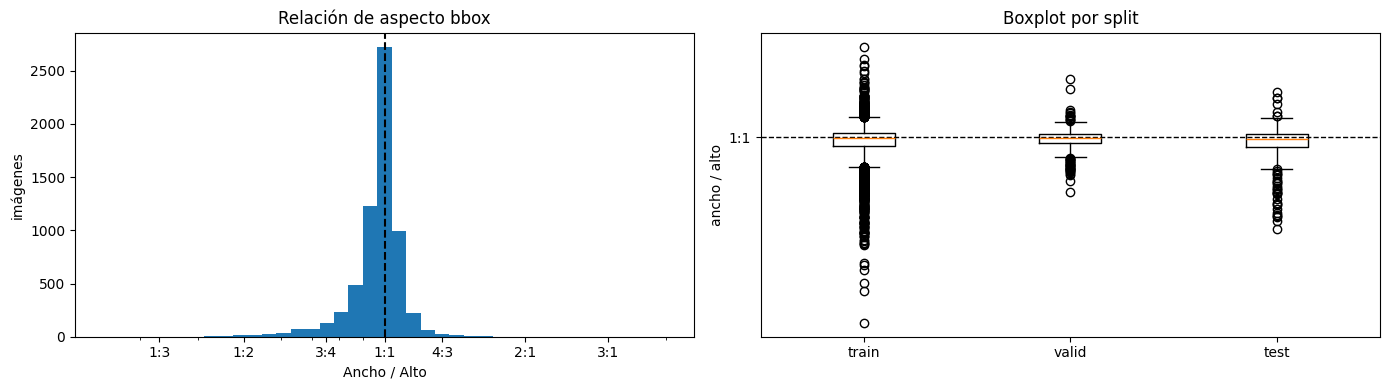

In [24]:
print(f"Cajas con más de un 20 % de diferencia respecto de 1:1 (aspecto < 0.8 o > 1.25): {((con_perro['aspect'] < 0.8) | (con_perro['aspect'] > 1.25)).mean():.1%}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

ax1.hist(con_perro["aspect"], bins=np.logspace(np.log10(0.25), np.log10(4), 40))
ax1.set_xscale("log")
ax1.set_xticks([0.33, 0.5, 0.75, 1, 1.33, 2, 3], ["1:3", "1:2", "3:4", "1:1", "4:3", "2:1", "3:1"])
ax1.axvline(1, color="k", ls="--", label="1:1")
ax1.set(title="Relación de aspecto bbox", xlabel="Ancho / Alto", ylabel="imágenes")

ax2.boxplot([con_perro.loc[con_perro["split"] == s, "aspect"] for s in SPLITS], tick_labels=SPLITS)
ax2.set_yscale("log")
ax2.set_yticks([1], ["1:1"])
ax2.minorticks_off()
ax2.axhline(1, color="k", ls="--", lw=1)
ax2.set(title="Boxplot por split", ylabel="ancho / alto")

plt.tight_layout()
plt.show()

Perros cuya bbox toca al menos un borde: 5157 (80.6% de las imágenes con perro)


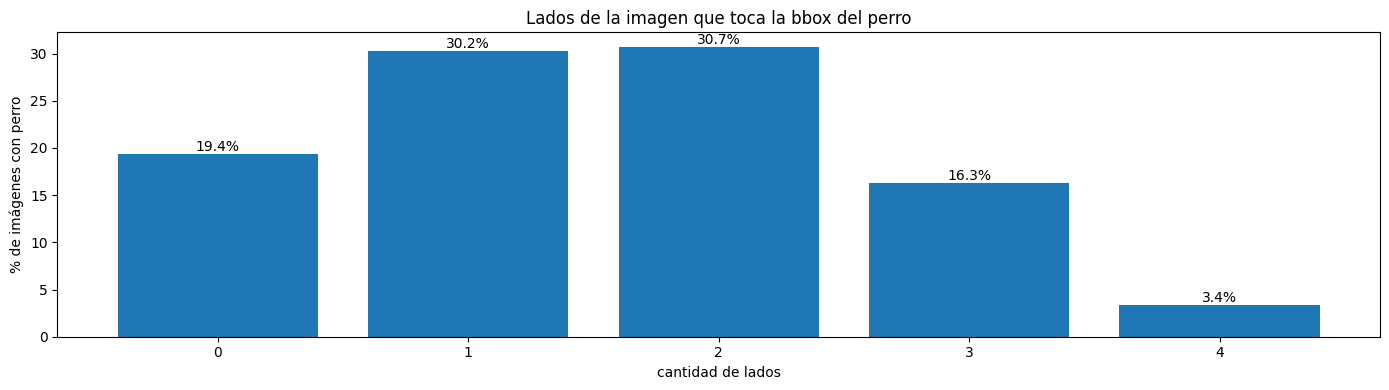

In [25]:
n_lados = con_perro["n_borders"].astype(int).value_counts().reindex(range(5), fill_value=0)
print(f"Perros cuya bbox toca al menos un borde: {(con_perro['n_borders'] >= 1).sum()} ({(con_perro['n_borders'] >= 1).mean():.1%} de las imágenes con perro)")

fig, ax = plt.subplots(figsize=(14, 4))
bars = ax.bar(n_lados.index, n_lados.values / len(con_perro) * 100)
ax.set_xticks(range(5))
ax.bar_label(bars, fmt="%.1f%%")
ax.set(title="Lados de la imagen que toca la bbox del perro", xlabel="cantidad de lados", ylabel="% de imágenes con perro")
plt.tight_layout()
plt.show()

In [26]:
sin_perro = frame[frame["n_dogs"] == 0]
print(f"Imágenes sin perro detectado (CONF >= {YOLO_CONF_THRESHOLD}): {len(sin_perro)}")

# Lo más confiable que ve YOLO en cada imagen sin perro (aunque esté por debajo del umbral)
mejor = (detections[detections["path"].isin(sin_perro["path"])].sort_values("conf", ascending=False).drop_duplicates("path").set_index("path"))
sin_perro = sin_perro.join(mejor[["cls_name", "conf"]].rename(columns={"conf": "conf_det"}), on="path")
sin_perro["asignado"] = np.where(sin_perro["cls_name"].isna(), "(nada, conf < 0.10)", np.where(sin_perro["conf_det"] < YOLO_CONF_THRESHOLD, sin_perro["cls_name"] + " (bajo umbral)", sin_perro["cls_name"]))
print("\nDetecciones más confiables en imágenes sin perro detectado:")
print(sin_perro["asignado"].value_counts().head(12).to_string())

print("\nRazas con más imágenes sin perro detectado (%):")
print((frame.groupby("breed")["n_dogs"].apply(lambda s: (s == 0).mean() * 100).sort_values(ascending=False).head(15).round(1).to_string()))

Imágenes sin perro detectado (CONF >= 0.25): 2951

Detecciones más confiables en imágenes sin perro detectado:
asignado
bear                  670
teddy bear            334
cat                   294
horse                 220
sheep                 208
bird                  205
person                162
cow                   158
giraffe               121
dog (bajo umbral)     113
elephant               88
bear (bajo umbral)     58

Razas con más imágenes sin perro detectado (%):
breed
Komondor            88.8
Irish Spaniel       81.3
Dhole               81.0
Coyote              78.6
Bichon Frise        71.2
Irish Wolfhound     65.2
Groenendael         64.0
Labradoodle         63.6
African Wild Dog    62.0
Poodle              59.9
American Spaniel    59.6
Newfoundland        59.2
Chow                51.5
Cockapoo            49.0
Mex Hairless        48.7


In [27]:
cs_sin_perro = frame.groupby("breed")["n_dogs"].apply(lambda s: (s == 0).mean() * 100)
print("Cánidos salvajes sin perro detectado (%):")
print(cs_sin_perro[["Coyote", "Dhole", "Dingo", "African Wild Dog"]].round(1).to_string())
print(f"\nMediana resto de razas: {cs_sin_perro.drop(["Coyote", "Dhole", "Dingo", "African Wild Dog"]).median():.1f}")

Cánidos salvajes sin perro detectado (%):
breed
Coyote              78.6
Dhole               81.0
Dingo               36.2
African Wild Dog    62.0

Mediana resto de razas: 23.9


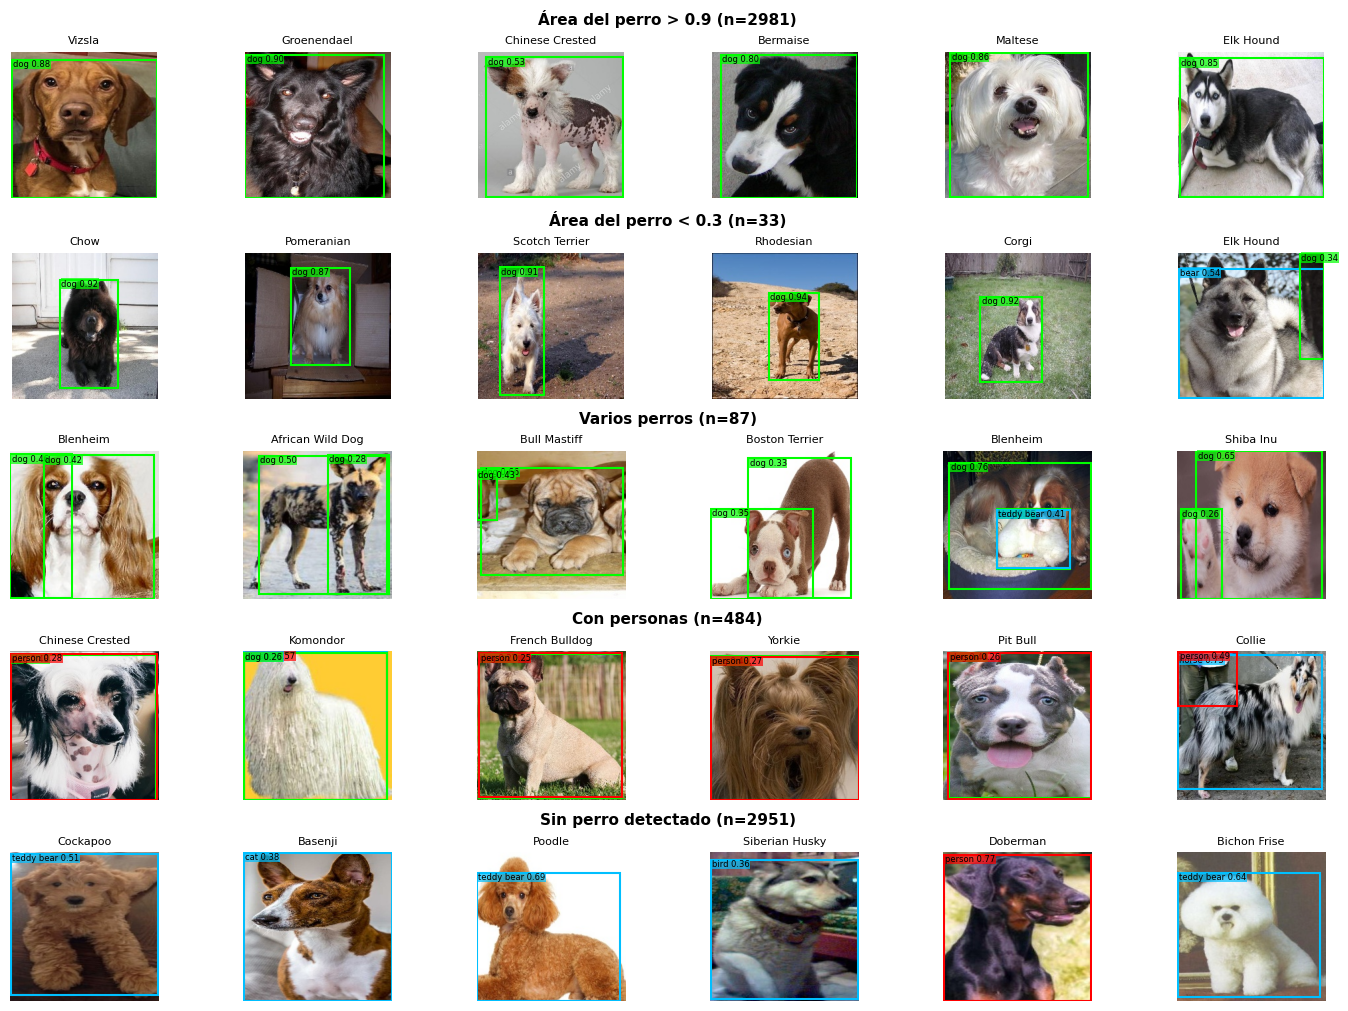

In [28]:
COLORS = {YOLO_DOG_CLASS_ID: "lime", YOLO_PERSON_CLASS_ID: "red"}
detections_ok = detections[detections["conf"] >= YOLO_CONF_THRESHOLD]
grupos = {
    "Área del perro > 0.9": frame[frame["area_frac"] > 0.9],
    "Área del perro < 0.3": frame[frame["area_frac"] < 0.3],
    "Varios perros": frame[frame["n_dogs"] >= 2],
    "Con personas": frame[frame["n_persons"] > 0],
    "Sin perro detectado": frame[frame["n_dogs"] == 0],
}
N_COLS = 6
fig = plt.figure(figsize=(14, 2 * len(grupos)), layout="constrained")
for subfig, (nombre, sub) in zip(fig.subfigures(len(grupos), 1), grupos.items()):
    subfig.suptitle(f"{nombre} (n={len(sub)})", fontsize=11, fontweight="bold")
    muestra = sub.sample(min(N_COLS, len(sub)), random_state=SEED)
    for col, ax in enumerate(subfig.subplots(1, N_COLS)):
        ax.axis("off")
        if col >= len(muestra):
            continue
        r = muestra.iloc[col]
        ax.imshow(Image.open(DATASET / r["path"]))
        for d in detections_ok[detections_ok["path"] == r["path"]].itertuples():
            color = COLORS.get(d.cls, "deepskyblue")
            ax.add_patch(patches.Rectangle((d.x1, d.y1), d.x2 - d.x1, d.y2 - d.y1, fill=False, lw=1.5, edgecolor=color))
            ax.text(d.x1 + 2, d.y1 + 10, f"{d.cls_name} {d.conf:.2f}", color="black", fontsize=6,
                    bbox=dict(facecolor=color, alpha=0.7, pad=0.5, lw=0))
        ax.set_title(r["breed"], fontsize=8)
plt.show()

**Conclusiones del encuadre**

**El dataset está formado por recortes cerrados sobre el perro.** En las imágenes donde YOLO detecta un perro (68 %), la bbox ocupa una mediana del **89 %** de la imagen, el **80,6 %** de los perros toca al menos un borde y las cajas son casi cuadradas (solo el 8,1 % se aleja más de un 20 % del 1:1), porque heredan el formato 224×224. Solo **33 de 9346** imágenes muestran al perro chico y con fondo visible.

**El detector se usa fuera de su dominio.** YOLO se entrenó con escenas completas (COCO), y sobre estos primeros planos falla: en el **31,6 %** de las imágenes no detecta ningún perro. No es falta de confianza (solo 113 de esas 2951 tienen un perro por debajo del umbral), sino un **error de especie**: los clasifica como `bear`, `teddy bear`, `cat`, `horse`, `sheep`, etc. Afecta sobre todo a razas de pelo largo o enrulado y a los cánidos salvajes.

**Los conteos de entidades no son confiables.** La grilla muestra que la mayoría de las personas (5,2 %) y de otros animales (30,6 %) son el propio perro mal clasificado, y que parte de las imágenes con dos o más perros (0,9 %) son cajas duplicadas sobre un mismo perro. Cualitativamente, las imágenes tienen un solo perro y casi no hay otras entidades.

**Comparación con lo que recibe el clasificador en la Etapa 3**

| Aspecto | Dataset | Recorte de YOLO (Etapa 3) |
|---|---|---|
| Encuadre | Recorte cerrado: el perro ocupa ~89 % y suele estar cortado | Caja ajustada al perro **entero** (si está entero en la foto) |
| Fondo | Mínimo | Mínimo, solo lo que queda dentro de la caja |
| Relación de aspecto | 1:1 (la caja hereda el formato) | La del perro: variable, no medible con este dataset |
| Resolución | Fija, 224×224 | Variable, según el tamaño del perro en la foto |
| Parte visible del perro | Muchas veces solo la cabeza o parte del cuerpo | Más seguido el cuerpo completo |

**Limitaciones que surgen de este análisis**

**El dataset es de recortes cerrados, no de fotos.** El clasificador aprende con primeros planos y partes del
  perro, pero en la Etapa 3 recibe recortes de YOLO con el perro entero, a otra resolución y relación de
  aspecto. La accuracy de `test` va a ser **optimista** respecto del uso real: el cambio de dominio se mide con
  el conjunto independiente (sección 6) y se puede mitigar con *random resized crop* en el augmentation
  (sección 8).

**Razas difíciles para el detector.** YOLO confunde con otras especies a las razas de pelo largo o enrulado
  y a la mayoría de los cánidos salvajes (Dhole 81 %, Coyote 78,6 %, African Wild Dog 62 % sin perro detectado;
  el Dingo, con 36,2 %, queda cerca del resto). En la Etapa 3, esas razas son candidatas a perderse **antes**
  de llegar al clasificador. Además, "YOLO no detecta un perro" no sirve como regla de descarte en el control de
  calidad (sección 5), porque eliminaría imágenes válidas.

## 5. Control de calidad y filtrado

TO-DO: reglas explícitas y reproducibles (archivos corruptos, baja resolución, imágenes borrosas o
con exposición extrema, duplicados y casi-duplicados dentro y entre splits, imágenes mal etiquetadas).
Reportar cuántas imágenes descarta cada regla y mostrar ejemplos de descartes.

In [29]:
## TO-DO: reglas de filtrado, conteo de descartes por regla y ejemplos.

## 6. Conjunto independiente de evaluación

TO-DO: imágenes que no pertenezcan al dataset (internet o fotos propias), con las mismas razas que
las carpetas del dataset. Incluir imágenes con un perro (Etapas 1 y 2), escenas con varios perros u
otros objetos e imágenes sin perros (Etapa 3). Documentar fuente y licencia; no subirlas al repositorio.

In [30]:
## TO-DO: construcción y resumen del conjunto independiente (por ejemplo, en data/dataset/independent/<raza>/).

## 7. Preprocesamiento

TO-DO: definir y justificar el resize, la normalización y el orden de canales (la app entrega BGR).

⚠️ El mismo preprocesamiento debe usarse en las notebooks y en los servicios de la app:
encapsulalo en un módulo de `src/lib/` e importalo desde ambos lados.

In [31]:
## TO-DO: transformaciones de preprocesamiento (importadas desde el módulo compartido).

## 8. Data augmentation

TO-DO: horizontal flip, rotación, blur, variaciones de brillo y contraste y ruido, con sus rangos
justificados. Mostrar una grilla de ejemplos aumentados de una misma imagen. Solo sobre `train`.

In [32]:
## TO-DO: pipeline de data augmentation con ejemplos visuales.

## 9. Splits

TO-DO: definir train / validation / test (los del dataset o redefinidos, justificando), verificar
que no haya fuga de datos entre splits, fijar semillas y guardar los splits finales (CSV/JSON con
rutas y etiquetas) para `2-train.ipynb`.

In [33]:
## TO-DO: splits finales, verificación de fuga de datos y exportación.

## 10. Resumen final

TO-DO: tabla con la cantidad de razas e imágenes por split, incluido el conjunto independiente.

In [34]:
## TO-DO: tabla resumen.

## 11. Licencias y uso de imágenes

TO-DO: licencia del dataset, fuente y licencia de las imágenes del conjunto independiente y criterio
aplicado a imágenes con personas identificables.